# Pre-entrega 10 · Predicción de cancelación de pólizas de automotores

El objetivo es identificar pólizas con riesgo de anulación para orientar acciones de retención. Se utiliza una cartera de seguros de automotores de 2024 y se toma la baja de una póliza como indicador de *churn*. La variable objetivo es `policy_status`, que distingue entre pólizas activas (`A`) y canceladas (`C`).

El problema se aborda mediante clasificación binaria. Luego de explorar y preparar los datos, se entrenan dos modelos, Regresión Logística y Random Forest. Se utiliza el 80 % de los registros para entrenamiento y el 20 % para prueba, manteniendo la proporción de pólizas activas y canceladas en ambos conjuntos.

El desempeño se evalúa mediante Accuracy, Precision, Recall, F1-score y la matriz de confusión. Se prioriza el **Recall de la clase cancelada** porque permite responder una pregunta de negocio: de todas las pólizas que se dieron de baja, ¿qué proporción logró detectar el modelo? Cada cancelación que pasa inadvertida representa una oportunidad perdida de contactar al asegurado antes de la baja.

In [19]:
#Importación de librerias

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

from sklearn.ensemble import RandomForestClassifier

sns.set_theme(style="whitegrid")

In [20]:
#Carga de datos

ruta_archivo = Path("data/raw/dataset.csv")

df = pd.read_csv(ruta_archivo)

print("Dataset cargado correctamente.")
print("Dimensiones:", df.shape)

display(df.head())


Dataset cargado correctamente.
Dimensiones: (168133, 47)


,insured_id,year,policy_type,policy_status,business_type,payment_frequency,bonus_score,driver_age,vehicle_age,age_driving_licence,...,liability_property_incurred,liability_injury_incurred,property_incurred,theft_incurred,fire_incurred,glass_incurred,legal_protection_incurred,occupants_incurred,total_exposure,liability_exposure
0,2,2024,COMP_E,A,P,A,G,45,26.0,18.0,...,1035.0,0.0,1551.3615,0.0,0.0,0.0,0.0,0.0,1.0,1.0
1,3,2024,COMP_E,A,P,S,G,47,28.0,19.0,...,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,1.0,1.0
2,4,2024,CC,A,P,A,G,34,14.0,19.0,...,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,1.0,1.0
3,5,2024,TPG,A,P,A,G,41,22.0,19.0,...,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,1.0,1.0
4,6,2024,CC,A,P,A,G,31,12.0,19.0,...,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,1.0,1.0


In [21]:
# Exploración de datos
print("Información general del dataset:")
df.info()

print("\nEstadísticas descriptivas:")
display(df.describe(include="all").T)

# Contamos los faltantes una sola vez
faltantes = df.isnull().sum()

print("\nValores faltantes por columna:")
display(faltantes[faltantes > 0].sort_values(ascending=False))

print("\nTotal de valores faltantes:", faltantes.sum())
print("Cantidad de registros duplicados:", df.duplicated().sum())

Información general del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 168133 entries, 0 to 168132
Data columns (total 47 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   insured_id                   168133 non-null  int64  
 1   year                         168133 non-null  int64  
 2   policy_type                  168133 non-null  object 
 3   policy_status                168133 non-null  object 
 4   business_type                168133 non-null  object 
 5   payment_frequency            168133 non-null  object 
 6   bonus_score                  168133 non-null  object 
 7   driver_age                   168133 non-null  int64  
 8   vehicle_age                  168132 non-null  float64
 9   age_driving_licence          168132 non-null  float64
 10  fuel_type                    167414 non-null  object 
 11  vehicle_value                167904 non-null  float64
 12  seats                    

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
insured_id,168133.0,NaN,NaN,NaN,98036.383286,52105.106096,2.0,55331.0,100451.0,142586.0,185678.0
year,168133.0,NaN,NaN,NaN,2024.0,0.0,2024.0,2024.0,2024.0,2024.0,2024.0
policy_type,168133,5,CC,96452,NaN,NaN,NaN,NaN,NaN,NaN,NaN
policy_status,168133,2,A,147349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
business_type,168133,2,NB,96402,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_frequency,168133,3,A,140030,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bonus_score,168133,3,G,163415,NaN,NaN,NaN,NaN,NaN,NaN,NaN
driver_age,168133.0,NaN,NaN,NaN,49.802484,12.055782,18.0,40.0,49.0,59.0,90.0
vehicle_age,168132.0,NaN,NaN,NaN,26.683522,11.63037,0.0,18.0,26.0,36.0,68.0
age_driving_licence,168132.0,NaN,NaN,NaN,23.003134,6.377806,0.0,19.0,20.0,25.0,80.0



Valores faltantes por columna:


fuel_type              719
vehicle_value          229
vehicle_age              1
age_driving_licence      1
dtype: int64


Total de valores faltantes: 950
Cantidad de registros duplicados: 0


Distribución de estados de póliza:


policy_status
A    147349
C     20784
Name: count, dtype: int64


Distribución porcentual:


policy_status
A    87.64
C    12.36
Name: proportion, dtype: float64

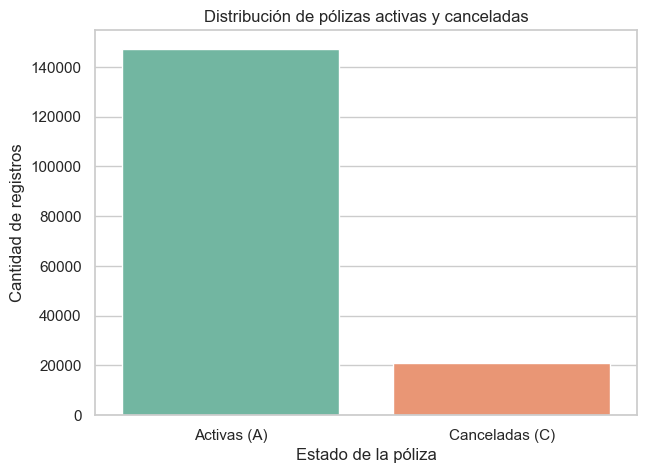

In [22]:
# La variable policy_status contiene:
    # A = Activa
    # C = Cancelada

print("Distribución de estados de póliza:")
display(df["policy_status"].value_counts())

print("\nDistribución porcentual:")
display(
    df["policy_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="policy_status",
    hue="policy_status",
    palette="Set2",
    legend=False
)

plt.title("Distribución de pólizas activas y canceladas")
plt.xlabel("Estado de la póliza")
plt.ylabel("Cantidad de registros")
plt.xticks([0, 1], ["Activas (A)", "Canceladas (C)"])
plt.show()



In [23]:
#Preparación de los datos

datos = df.copy()

# Eliminamos registros sin variable objetivo.
datos = datos.dropna(subset=["policy_status"])

# Codificación de la variable objetivo:
# 0 = Activa
# 1 = Cancelada

datos["policy_status"] = datos["policy_status"].map({
    "A": 0,
    "C": 1
})

# Eliminamos registros que no tengan una categoría válida.
datos = datos.dropna(subset=["policy_status"])

datos["policy_status"] = datos["policy_status"].astype(int)

# Eliminamos el identificador porque no aporta información
# generalizable para el modelo.
columnas_a_eliminar = ["insured_id"]

# Excluimos variables de siniestros, costos incurridos y exposición. Se evita utilizarlas como predictores porque pueden contener información posterior o relacionada con el resultado observado.
columnas_a_eliminar += [
    col for col in datos.columns
    if col.endswith(("_claims", "_incurred", "_exposure"))
]

# Evitamos duplicados en la lista.
columnas_a_eliminar = list(set(columnas_a_eliminar))

# Separamos las variables predictoras de la variable objetivo.
X = datos.drop(
    columns=["policy_status"] + columnas_a_eliminar,
    errors="ignore"
)

y = datos["policy_status"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print("\nDistribución de la variable objetivo:")
display(y.value_counts())


Dimensiones de X: (168133, 23)
Dimensiones de y: (168133,)

Distribución de la variable objetivo:


policy_status
0    147349
1     20784
Name: count, dtype: int64

In [24]:
# Identificación de variables numéricas y categóricas

columnas_numericas = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

columnas_categoricas = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Variables numéricas:")
print(columnas_numericas)

print("\nVariables categóricas:")
print(columnas_categoricas)

Variables numéricas:
['year', 'driver_age', 'vehicle_age', 'age_driving_licence', 'vehicle_value', 'seats', 'power_to_weight_ratio', 'total_premium', 'liability_premium', 'property_damage_premium', 'theft_premium', 'fire_premium', 'glass_premium', 'legal_protection_premium', 'occupants_premium']

Variables categóricas:
['policy_type', 'business_type', 'payment_frequency', 'bonus_score', 'fuel_type', 'vehicle_brand', 'municipality_type', 'circulation_area']


In [25]:
#Division en train y test (80/20)
# stratify=y mantiene la proporción de clases en ambos conjuntos.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Cantidad de registros para entrenamiento:", X_train.shape[0])
print("Cantidad de registros para prueba:", X_test.shape[0])

print("\nDistribución porcentual en entrenamiento:")
display(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nDistribución porcentual en prueba:")
display(y_test.value_counts(normalize=True).mul(100).round(2))


Cantidad de registros para entrenamiento: 134506
Cantidad de registros para prueba: 33627

Distribución porcentual en entrenamiento:


policy_status
0    87.64
1    12.36
Name: proportion, dtype: float64


Distribución porcentual en prueba:


policy_status
0    87.64
1    12.36
Name: proportion, dtype: float64

In [26]:
# Analizar importes altos del premio total y de cada cobertura
premios = X_train.filter(regex="_premium$")

# Calcular los límites entre las pólizas con importe positivo
positivos = premios.where(premios > 0)
q1 = positivos.quantile(0.25)
q3 = positivos.quantile(0.75)
limite_superior = q3 + 1.5 * (q3 - q1)

# Resumir los resultados por variable
resumen_premios = pd.DataFrame({
    "Importes en cero": (premios == 0).sum(),
    "Límite superior": limite_superior,
    "Casos por encima": (premios > limite_superior).sum(),
    "Máximo": premios.max()
})

display(resumen_premios.round(2))

,Importes en cero,Límite superior,Casos por encima,Máximo
total_premium,39,745.50,5657,5104.21
liability_premium,49,447.77,3808,2160.16
property_damage_premium,91878,604.16,2205,3736.73
theft_premium,15735,33.86,9016,1038.51
fire_premium,15738,4.46,9275,55.11
glass_premium,2457,57.14,4824,372.47
legal_protection_premium,49,22.19,6970,175.06
occupants_premium,49,5.25,2334,12.64


In [27]:
# Revisar las pólizas con premio total igual a cero
premio_cero = X_train[X_train["total_premium"] == 0]
coberturas = premio_cero.filter(regex="_premium$").drop(columns="total_premium")

print("Pólizas con premio total cero:", len(premio_cero))
print("Con todas las coberturas en cero:", coberturas.eq(0).all(axis=1).sum())
print("Con alguna cobertura positiva:", coberturas.gt(0).any(axis=1).sum())

display(premio_cero[["policy_type", "business_type", "total_premium",
                     *coberturas.columns]].head(10))

Pólizas con premio total cero: 39
Con todas las coberturas en cero: 39
Con alguna cobertura positiva: 0


,policy_type,business_type,total_premium,liability_premium,property_damage_premium,theft_premium,fire_premium,glass_premium,legal_protection_premium,occupants_premium
54609,CC,P,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
14841,CC,P,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2058,COMP_E,P,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
161740,CC,P,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
53506,CC,P,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
83141,CC,NB,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
163198,CC,P,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5542,TPG,P,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9752,CC,P,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
163330,CC,NB,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


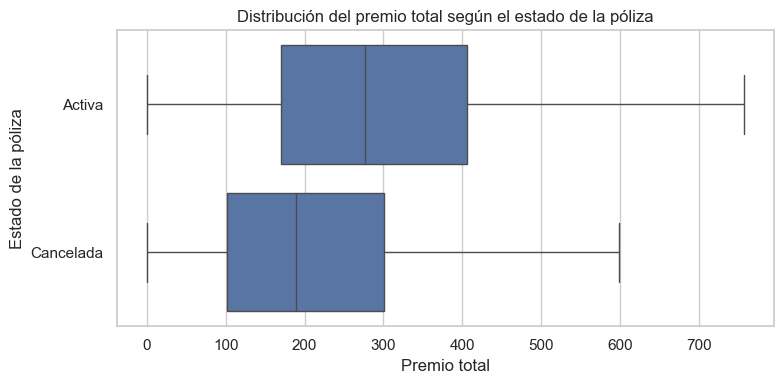

In [28]:
# Distribución del premio total según el estado de la póliza

datos_grafico = X_train[["total_premium"]].copy()
datos_grafico["estado"] = y_train.map({0: "Activa", 1: "Cancelada"})

plt.figure(figsize=(8, 4))
sns.boxplot(
    data=datos_grafico,
    x="total_premium",
    y="estado",
    order=["Activa", "Cancelada"],
    showfliers=False
)
plt.title("Distribución del premio total según el estado de la póliza")
plt.xlabel("Premio total")
plt.ylabel("Estado de la póliza")
plt.tight_layout()
plt.show()

In [29]:
#Pipeline de procesamiento

# - Se reemplazan valores faltantes con la mediana.
# - Se aplica StandardScaler para normalizar las variables.


# Para las variables numéricas:
# - Se reemplazan valores faltantes con la mediana.
# - Se aplica StandardScaler para normalizar las variables.

transformador_numerico = Pipeline(
    steps=[
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler())
    ]
)

# Para las variables categóricas:
# - Se reemplazan valores faltantes con la categoría más frecuente.
# - Se aplica OneHotEncoder para convertir categorías en números.

transformador_categorico = Pipeline(
    steps=[
        ("imputador", SimpleImputer(strategy="most_frequent")),
        ("codificador", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Se combinan procesos de transformación.

preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", transformador_numerico, columnas_numericas),
        ("categoricas", transformador_categorico, columnas_categoricas)
    ]
)



In [30]:
# Construcción del modelo - Regresión Logistica

modelo = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        (
            "clasificador",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

print("Pipeline creado correctamente.")

Pipeline creado correctamente.


In [31]:
# Entrenamiento del modelo

modelo.fit(X_train, y_train)

print("Modelo entrenado correctamente.")



Modelo entrenado correctamente.


In [32]:
# Predicciones de las clases.
y_pred = modelo.predict(X_test)

# Probabilidades de pertenecer a la clase cancelada (1).
y_proba = modelo.predict_proba(X_test)[:, 1]

print("Primeras 10 predicciones:")
print(y_pred[:10])


Primeras 10 predicciones:
[0 0 0 0 1 1 0 0 0 0]


In [33]:
# Evaluación del modelo

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(y_test, y_proba)

metricas = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC AUC"
    ],
    "Resultado": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

metricas["Resultado"] = metricas["Resultado"].round(4)

print("Métricas de evaluación:")
display(metricas)

Métricas de evaluación:


,Métrica,Resultado
0,Accuracy,0.6693
1,Precision,0.2217
2,Recall,0.6671
3,F1-score,0.3328
4,ROC AUC,0.7460


In [34]:
# Reporte de Clasificacion

print("Reporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Activa", "Cancelada"],
        zero_division=0
    )
)


Reporte de clasificación:
              precision    recall  f1-score   support

      Activa       0.93      0.67      0.78     29470
   Cancelada       0.22      0.67      0.33      4157

    accuracy                           0.67     33627
   macro avg       0.58      0.67      0.56     33627
weighted avg       0.85      0.67      0.72     33627



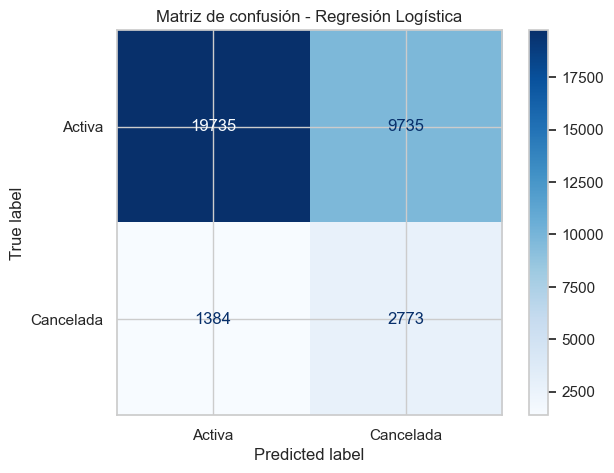

In [35]:
# Matriz de confusion

matriz = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Activa", "Cancelada"]
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Matriz de confusión - Regresión Logística")
plt.show()

In [36]:
#Analisis de falsos positivos y negativos

tn, fp, fn, tp = matriz.ravel()

print("Verdaderos negativos (TN):", tn)
print("Falsos positivos (FP):", fp)
print("Falsos negativos (FN):", fn)
print("Verdaderos positivos (TP):", tp)

print("\nInterpretación:")

print(
    f"El modelo identificó correctamente {tp} pólizas canceladas."
)

print(
    f"El modelo no detectó {fn} pólizas que estaban canceladas "
    "y predijo que seguían activas."
)

print(
    f"El modelo identificó correctamente {tn} pólizas activas."
)

print(
    f"El modelo clasificó incorrectamente {fp} pólizas activas "
    "como canceladas."
)


Verdaderos negativos (TN): 19735
Falsos positivos (FP): 9735
Falsos negativos (FN): 1384
Verdaderos positivos (TP): 2773

Interpretación:
El modelo identificó correctamente 2773 pólizas canceladas.
El modelo no detectó 1384 pólizas que estaban canceladas y predijo que seguían activas.
El modelo identificó correctamente 19735 pólizas activas.
El modelo clasificó incorrectamente 9735 pólizas activas como canceladas.


,Umbral,Precision,Recall,F1-score
0,0.2,0.1370,0.9649,0.2399
1,0.3,0.1520,0.8946,0.2598
2,0.4,0.1723,0.7965,0.2833
3,0.5,0.2217,0.6671,0.3328
4,0.6,0.3285,0.5249,0.4041
5,0.7,0.5522,0.3827,0.4521


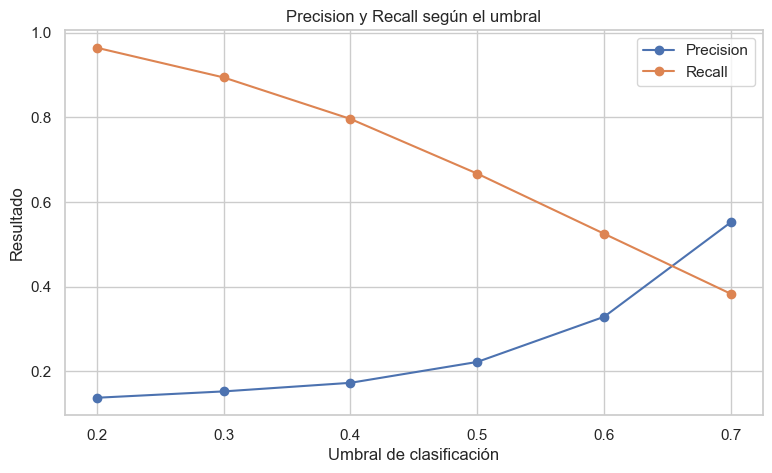

In [37]:
# Analisis de umbral de clasificación El umbral predeterminado de clasificación es 0.5.
# - Se analiza cómo cambian Precision y Recall al modificarlo.

umbrales = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

resultados_umbrales = []

for umbral in umbrales:

    predicciones_umbral = (y_proba >= umbral).astype(int)

    precision_umbral = precision_score(
        y_test,
        predicciones_umbral,
        zero_division=0
    )

    recall_umbral = recall_score(
        y_test,
        predicciones_umbral,
        zero_division=0
    )

    f1_umbral = f1_score(
        y_test,
        predicciones_umbral,
        zero_division=0
    )

    resultados_umbrales.append({
        "Umbral": umbral,
        "Precision": precision_umbral,
        "Recall": recall_umbral,
        "F1-score": f1_umbral
    })

df_umbrales = pd.DataFrame(resultados_umbrales)

display(df_umbrales.round(4))


# Gráfico de Precision y Recall según el umbral.

plt.figure(figsize=(9, 5))

plt.plot(
    df_umbrales["Umbral"],
    df_umbrales["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    df_umbrales["Umbral"],
    df_umbrales["Recall"],
    marker="o",
    label="Recall"
)

plt.title("Precision y Recall según el umbral")
plt.xlabel("Umbral de clasificación")
plt.ylabel("Resultado")
plt.legend()
plt.grid(True)
plt.show()



In [38]:
# Conclusión del modelo

print("CONCLUSIÓN DEL MODELO")
print("=" * 55)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")

print("\nAnálisis del problema de negocio:")

print(
    f"De las pólizas canceladas reales, el modelo detectó "
    f"{tp} correctamente y no detectó {fn}."
)

print(
    f"El Recall para la clase cancelada fue de {recall:.2%}."
)

print(
    "Esta métrica es importante porque permite medir qué "
    "proporción de las pólizas canceladas logra identificar "
    "el modelo."
)



CONCLUSIÓN DEL MODELO
Accuracy: 0.6693
Precision: 0.2217
Recall: 0.6671
F1-score: 0.3328
ROC AUC: 0.7460

Análisis del problema de negocio:
De las pólizas canceladas reales, el modelo detectó 2773 correctamente y no detectó 1384.
El Recall para la clase cancelada fue de 66.71%.
Esta métrica es importante porque permite medir qué proporción de las pólizas canceladas logra identificar el modelo.


In [39]:
# Comparacion de modelos - random forest


modelo_rf = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),

        ("clasificador", RandomForestClassifier(
            n_estimators=50,
            max_depth=10,
            min_samples_leaf=5,
            max_features="sqrt",
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Entrenamiento
modelo_rf.fit(X_train, y_train)

print("Random Forest entrenado correctamente.")

# Predicciones
y_pred_rf = modelo_rf.predict(X_test)

y_proba_rf = modelo_rf.predict_proba(X_test)[:, 1]

Random Forest entrenado correctamente.


In [40]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf, zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, zero_division=0)
roc_auc_rf = roc_auc_score(y_test, y_proba_rf)

print("RESULTADOS RANDOM FOREST")
print("------------------------")
print("Accuracy:", round(accuracy_rf, 4))
print("Precision:", round(precision_rf, 4))
print("Recall:", round(recall_rf, 4))
print("F1-score:", round(f1_rf, 4))
print("ROC AUC:", round(roc_auc_rf, 4))

RESULTADOS RANDOM FOREST
------------------------
Accuracy: 0.8339
Precision: 0.3837
Recall: 0.5668
F1-score: 0.4576
ROC AUC: 0.8091


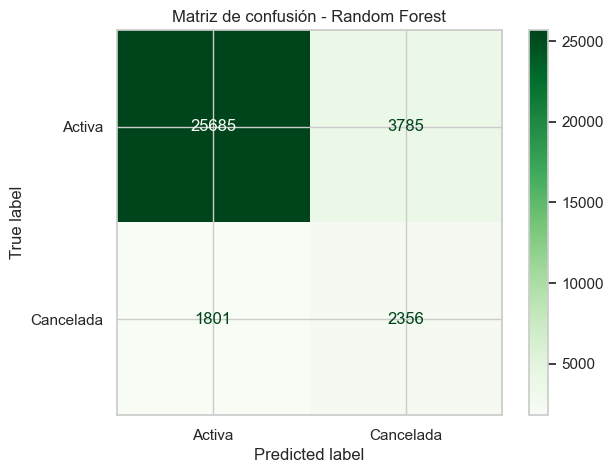

In [41]:
# Matriz de confusion

matriz_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_rf,
    display_labels=["Activa", "Cancelada"]
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(
    cmap="Greens",
    values_format="d",
    ax=ax
)

plt.title("Matriz de confusión - Random Forest")
plt.show()

In [42]:

# COMPARACIÓN DE MODELOS

comparacion = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC AUC"
    ],

    "Regresión Logística": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_proba)
    ],

    "Random Forest": [
        accuracy_rf,
        precision_rf,
        recall_rf,
        f1_rf,
        roc_auc_rf
    ]
})

display(comparacion.round(4))

,Métrica,Regresión Logística,Random Forest
0,Accuracy,0.6693,0.8339
1,Precision,0.2217,0.3837
2,Recall,0.6671,0.5668
3,F1-score,0.3328,0.4576
4,ROC AUC,0.7460,0.8091


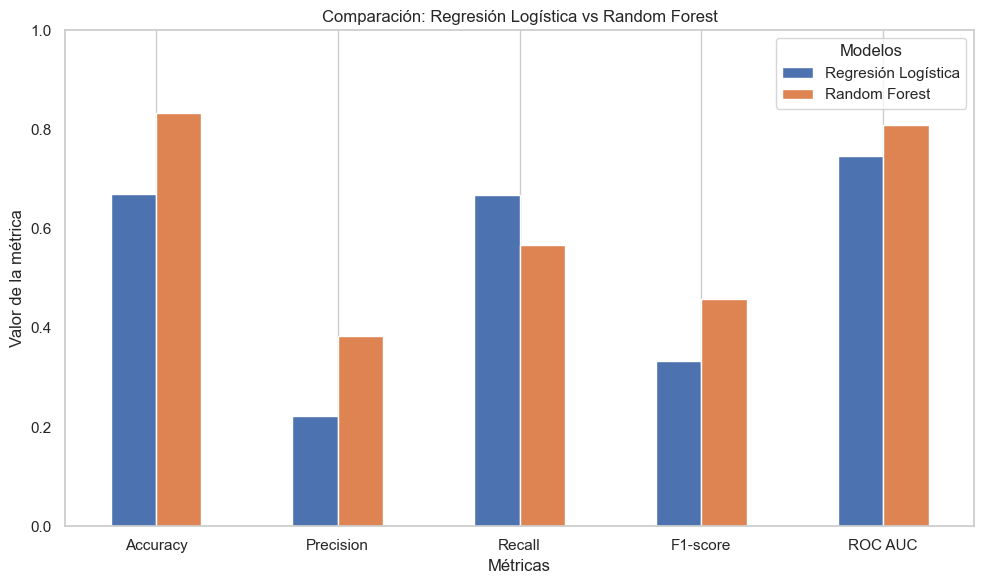

In [43]:
# Gráfico comparativo
comparacion_grafico = comparacion.set_index("Métrica")

comparacion_grafico.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparación: Regresión Logística vs Random Forest")
plt.ylabel("Valor de la métrica")
plt.xlabel("Métricas")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Modelos")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [44]:
# Comparación del desempeño en entrenamiento y prueba
resultados = []

for nombre, clasificador in [
    ("Regresión logística", modelo),
    ("Random Forest", modelo_rf)
]:
    pred_train = clasificador.predict(X_train)
    pred_test = clasificador.predict(X_test)

    resultados.append({
        "Modelo": nombre,
        "Recall train": recall_score(y_train, pred_train),
        "Recall test": recall_score(y_test, pred_test),
        "F1 train": f1_score(y_train, pred_train),
        "F1 test": f1_score(y_test, pred_test)
    })

display(pd.DataFrame(resultados).round(4))

,Modelo,Recall train,Recall test,F1 train,F1 test
0,Regresión logística,0.6624,0.6671,0.3291,0.3328
1,Random Forest,0.6131,0.5668,0.4941,0.4576


Conclusión e impacto en el negocio

En este trabajo se tomó la cancelación de una póliza como indicador de churn. La regresión logística detectó 2.773 de las 4.157 pólizas que efectivamente se cancelaron en el conjunto de prueba. Esto representa un Recall del 66,71 %.

Para una campaña de retención, priorizaría el Recall de la clase «Cancelada». Las 1.384 cancelaciones que el modelo clasificó como activas son falsos negativos. Si la aseguradora usara las alertas para decidir sobre qué universo accionar, esas pólizas quedarían fuera de posibles campañas y se perdería la oportunidad de intervenir antes de la anulación.

La Precision fue del 22,17 %: de cada 100 alertas, aproximadamente 22 correspondieron a pólizas que se cancelaron. Las 9.734 falsas alertas implicarían dedicar tiempo de gestión a pólizas que siguieron activas. Por eso, además de medir cuántas bajas detecta el modelo, la aseguradora tendría que considerar cuántos contactos puede gestionar.